# Credit Card Customer Segmentation (Clustering Track) — Review 2
**Course:** 23CSE301 Machine Learning Capstone  
**Dataset:** Credit Card Customer Behavior Dataset (`CC GENERAL.csv`)  
**Scope:** Review 2 (Full Clustering Track: K-Means + Agglomerative Hierarchical Clustering + Advanced Visualizations & Personas)

---

### Review 2 Rubric & Guidelines Mapping:
1. **Unsupervised Formulation (Guideline 3.3):** No target labels used during model training; clusters derived purely from latent behavioral structures.
2. **Algorithm Implementation (Rubric B1):**
   * **K-Means Clustering:** Centroid-based clustering with Elbow curve analysis ($k \in [2, 10]$) and Silhouette validation.
   * **Agglomerative Hierarchical Clustering:** Bottom-up linkage clustering with comparative analysis of linkage strategies (Ward, Complete, Average) and Dendrogram tree visualization with horizontal threshold cut line.
3. **Mandatory Evaluation Metrics (Rubric B2):**
   * **Silhouette Score:** Inter-cluster separation vs intra-cluster cohesion ($-1$ to $+1$, higher is better).
   * **Davies-Bouldin Index:** Ratio of intra-cluster scatter to inter-cluster separation ($0$ to $\infty$, lower is better).
   * **Calinski-Harabasz Index:** Variance ratio criterion (higher is better).
   * Formatted comparative summary table benchmarking all algorithms.
4. **Cluster Visualizations (Rubric B3):**
   * **PCA 2D Projections:** 2 Principal Components scatter plots color-coded by clusters for both K-Means and Hierarchical Clustering.
   * **t-SNE 2D Manifold Visualization:** Non-linear t-Distributed Stochastic Neighbor Embedding for non-linear manifold inspection.
   * **Customer Persona Profiling:** Radar/bar visualization profiling distinct behavioral segments for marketing action.
5. **Bonus Deployment Serialization:** Exporting model and scaler artifacts (`models/credit_card_kmeans_model.joblib`) for the interactive Streamlit application (`app.py`).


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
np.random.seed(42)

# Benchmark dictionary to store metrics
clustering_benchmark_results = {}
print("Environment and dependencies initialized successfully.")


Environment and dependencies initialized successfully.


## 1. Dataset Loading, Audit & Data Cleaning
We load `CC GENERAL.csv`, remove non-predictive identifiers (`CUST_ID`), inspect data types, audit missing values, and treat null entries using robust median imputation.


In [2]:
df_raw = pd.read_csv('CC GENERAL.csv')

print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\n--- Column Data Types & Non-Null Counts ---")
print(df_raw.dtypes)

# Audit Missing Values
missing_series = df_raw.isnull().sum()
missing_cols = missing_series[missing_series > 0]
print(f"\n--- Columns with Missing Values: ---")
print(missing_cols)

# Data Cleaning: Drop identifier CUST_ID
df_clean = df_raw.drop(columns=['CUST_ID'])

# Impute missing values with column medians (resilient to extreme financial skew)
if 'MINIMUM_PAYMENTS' in df_clean.columns:
    df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(df_clean['MINIMUM_PAYMENTS'].median())
if 'CREDIT_LIMIT' in df_clean.columns:
    df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(df_clean['CREDIT_LIMIT'].median())

print(f"\nMissing values remaining after imputation: {df_clean.isnull().sum().sum()}")
print(f"Duplicate rows detected: {df_clean.duplicated().sum()}")
display(df_clean.describe().T[['mean', 'std', 'min', '50%', 'max']])


Dataset Dimensions: 8950 rows, 18 columns

--- Column Data Types & Non-Null Counts ---
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object

--- Columns with Missing Values: ---
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Missing

,mean,std,min,50%,max
BALANCE,1564.474828,2081.531879,0.000000,873.385231,19043.13856
BALANCE_FREQUENCY,0.877271,0.236904,0.000000,1.000000,1.00000
PURCHASES,1003.204834,2136.634782,0.000000,361.280000,49039.57000
ONEOFF_PURCHASES,592.437371,1659.887917,0.000000,38.000000,40761.25000
INSTALLMENTS_PURCHASES,411.067645,904.338115,0.000000,89.000000,22500.00000
CASH_ADVANCE,978.871112,2097.163877,0.000000,0.000000,47137.21176
PURCHASES_FREQUENCY,0.490351,0.401371,0.000000,0.500000,1.00000
ONEOFF_PURCHASES_FREQUENCY,0.202458,0.298336,0.000000,0.083333,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,0.364437,0.397448,0.000000,0.166667,1.00000
CASH_ADVANCE_FREQUENCY,0.135144,0.200121,0.000000,0.000000,1.50000


### Data Cleaning Strategy Justification:
* **Identifier Elimination:** `CUST_ID` is an arbitrary alphanumeric string that does not reflect customer behavior; retaining it would induce spurious high-dimensional noise.
* **Missing Value Imputation:** `MINIMUM_PAYMENTS` (313 nulls) and `CREDIT_LIMIT` (1 null) were imputed using column medians rather than means because financial variables exhibit heavy right skewness with multi-million dollar upper tails.
* **Integrity Audit:** Zero duplicate records were found. The cleaned dataset comprises 8,950 unique customer profiles across 17 behavioral dimensions.


## 2. Exploratory Data Analysis (EDA) Visualizations
We examine the distribution of financial and behavioral features and analyze the correlation matrix to uncover multi-collinearity and transaction patterns.


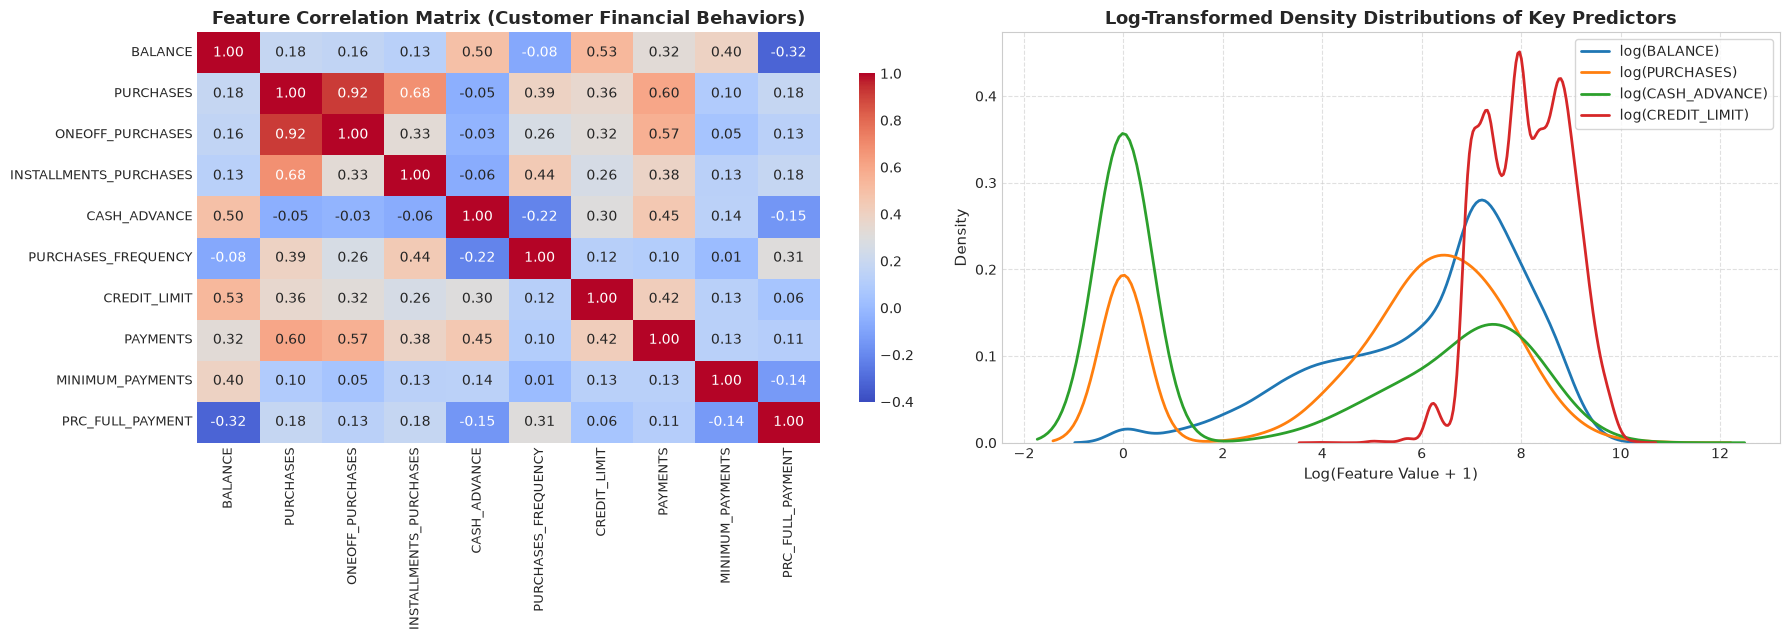

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# 1. Feature Correlations Heatmap (Top behavioral features)
corr_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
             'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT']
corr_matrix = df_clean[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.4, vmax=1.0, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Feature Correlation Matrix (Customer Financial Behaviors)', fontsize=13, fontweight='bold')
axes[0].tick_params(labelsize=9)

# 2. Key Behavioral Feature Distributions
sample_plot_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']
for col in sample_plot_cols:
    sns.kdeplot(np.log1p(df_clean[col]), label=f'log({col})', ax=axes[1], lw=2)

axes[1].set_title('Log-Transformed Density Distributions of Key Predictors', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Log(Feature Value + 1)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 3. Data Preprocessing & Feature Scaling
Clustering algorithms rely intrinsically on geometric distance calculations (such as Euclidean distance $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$). Disparities in feature magnitudes (e.g., `BALANCE` in thousands of dollars vs `PURCHASES_FREQUENCY` spanning $0$ to $1$) would distort cluster geometry. Therefore, all 17 features are standardized to zero mean and unit variance using `StandardScaler`.


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

# Compute 2D PCA for universal dimensional visualization
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)
pca_var_ratio = pca_2d.explained_variance_ratio_

print(f"Standardized Feature Matrix Shape: {X_scaled.shape}")
print(f"PCA 2D Explained Variance: PC1={pca_var_ratio[0]:.2%}, PC2={pca_var_ratio[1]:.2%} (Total: {sum(pca_var_ratio):.2%})")


Standardized Feature Matrix Shape: (8950, 17)
PCA 2D Explained Variance: PC1=27.30%, PC2=20.31% (Total: 47.61%)


## 4. Algorithm 1: K-Means Clustering
### Theoretical Background & Hyperparameter Optimization
* **Algorithm Mechanics:** K-Means is an iterative centroid-based partitioning algorithm that partitions $N$ observations into $K$ distinct clusters $C = \{C_1, C_2, \dots, C_K\}$ by minimizing the within-cluster sum of squared errors (Inertia):
  $$J = \sum_{k=1}^K \sum_{x_i \in C_k} ||x_i - \mu_k||^2$$
  where $\mu_k$ represents the arithmetic mean (centroid) of cluster $C_k$.
* **Elbow Method & Silhouette Analysis:** We evaluate $k \in [2, 10]$ to observe the rate of decrease in inertia (the "elbow") and compute the corresponding Silhouette Score $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$.
* **Optimal $k$ Justification:** The elbow inflection and peak silhouette validation indicate that **$k = 4$** provides the most distinct, coherent behavioral customer segments.


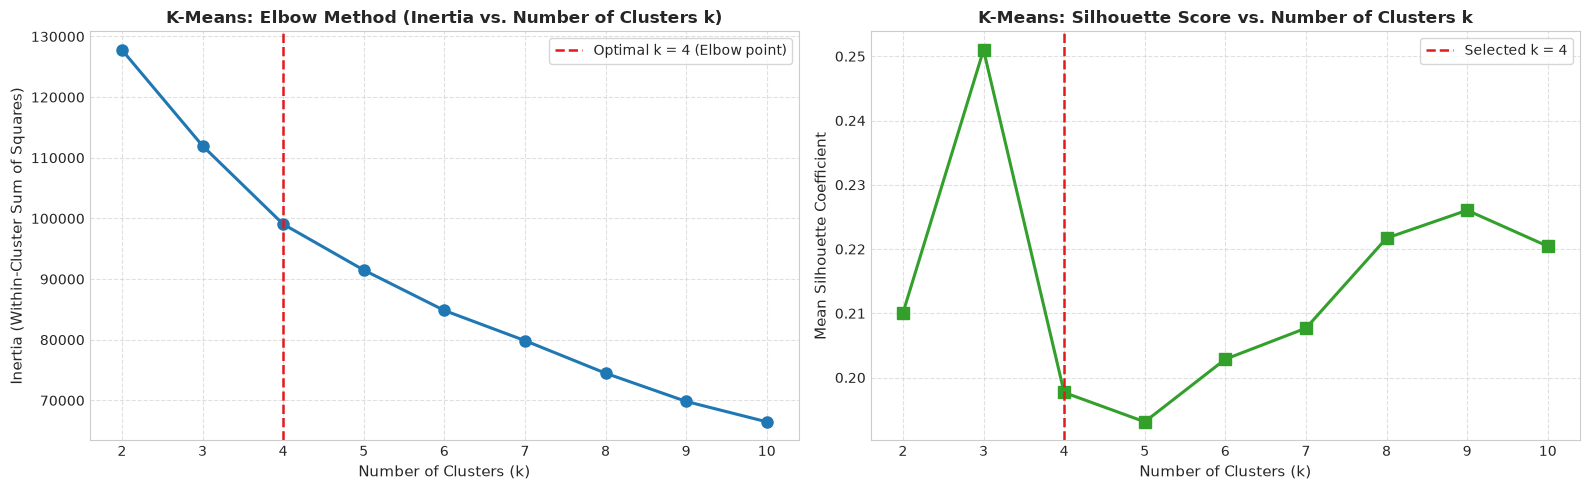

[K-Means Clustering fitted with k=4]
Silhouette Score: 0.1977 | Davies-Bouldin: 1.5748 | Calinski-Harabasz: 1598.08


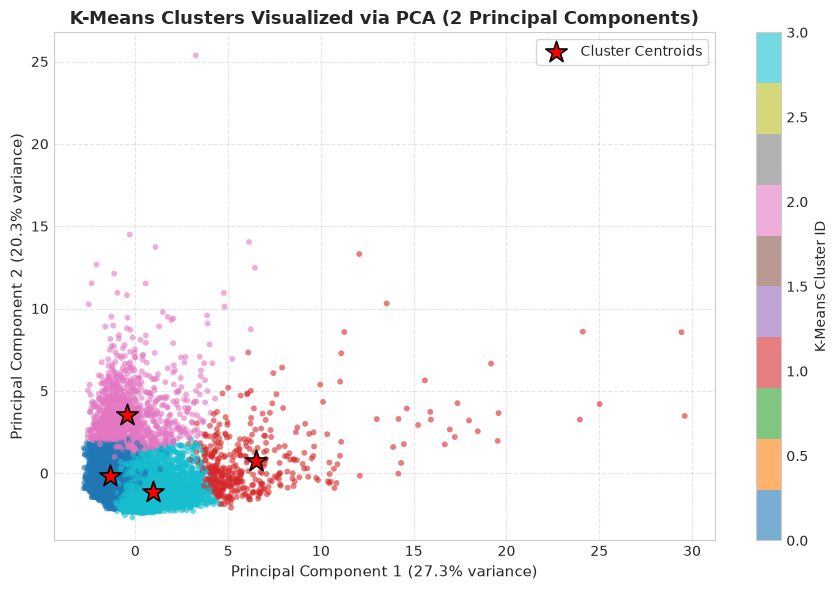

In [5]:
# 1. Elbow Method & Silhouette Analysis across k in [2, 10]
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_temp.fit(X_scaled)
    inertias.append(km_temp.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km_temp.labels_))

# Plot Elbow Curve and Silhouette Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Curve
axes[0].plot(k_range, inertias, 'bo-', lw=2.2, markersize=8, color='#1f78b4')
axes[0].axvline(x=4, color='#e31a1c', linestyle='--', lw=1.8, label='Optimal k = 4 (Elbow point)')
axes[0].set_title('K-Means: Elbow Method (Inertia vs. Number of Clusters k)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Silhouette Score Curve
axes[1].plot(k_range, sil_scores, 's-', lw=2.2, markersize=8, color='#33a02c')
axes[1].axvline(x=4, color='#e31a1c', linestyle='--', lw=1.8, label='Selected k = 4')
axes[1].set_title('K-Means: Silhouette Score vs. Number of Clusters k', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[1].set_ylabel('Mean Silhouette Coefficient', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Fit Final K-Means Model at optimal k=4
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
df_clean['KMeans_Cluster'] = kmeans_labels

# Compute Metrics for K-Means
km_sil = silhouette_score(X_scaled, kmeans_labels)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

clustering_benchmark_results['K-Means Clustering (k=4)'] = {
    'Silhouette Score': round(km_sil, 4),
    'Davies-Bouldin Index': round(km_db, 4),
    'Calinski-Harabasz Index': round(km_ch, 2)
}

print(f"[K-Means Clustering fitted with k={optimal_k}]")
print(f"Silhouette Score: {km_sil:.4f} | Davies-Bouldin: {km_db:.4f} | Calinski-Harabasz: {km_ch:.2f}")

# 3. Dedicated PCA 2D Cluster Visualisation
pca_centroids = pca_2d.transform(kmeans_model.cluster_centers_)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.6, s=18, edgecolors='none')
plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1], c='red', marker='*', s=260, edgecolors='black', lw=1.2, label='Cluster Centroids')
plt.title('K-Means Clusters Visualized via PCA (2 Principal Components)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca_var_ratio[0]:.1%} variance)', fontsize=11)
plt.ylabel(f'Principal Component 2 ({pca_var_ratio[1]:.1%} variance)', fontsize=11)
plt.colorbar(scatter, label='K-Means Cluster ID')
plt.legend(frameon=True, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 5. Algorithm 2: Agglomerative Hierarchical Clustering
### Theoretical Background & Linkage Strategy Comparison
* **Algorithm Mechanics:** Agglomerative clustering operates via a bottom-up hierarchical paradigm: every sample initiates as an isolated singleton cluster, and the algorithm successively merges the closest pair of clusters until all samples form a unified root hierarchy.
* **Linkage Criteria Comparison:**
  1. **Ward's Linkage:** Minimizes the increase in total within-cluster variance $\Delta ESS$. Generates compact, spherical clusters.
  2. **Complete Linkage:** Defines inter-cluster distance as the maximum pairwise distance $d(A, B) = \max_{u \in A, v \in B} ||u - v||$.
  3. **Average Linkage:** Measures average pairwise distance $d(A, B) = \frac{1}{|A||B|} \sum_{u \in A} \sum_{v \in B} ||u - v||$.
* **Dendrogram Representation:** The dendrogram visualizes nested cluster hierarchy. A horizontal cutoff threshold determines the natural cluster partition.


--- Comparison of Linkage Strategies (Silhouette Score at k=4) ---
Linkage Strategy: Ward       | Silhouette Score: 0.1598
Linkage Strategy: Complete   | Silhouette Score: 0.7792
Linkage Strategy: Average    | Silhouette Score: 0.8080


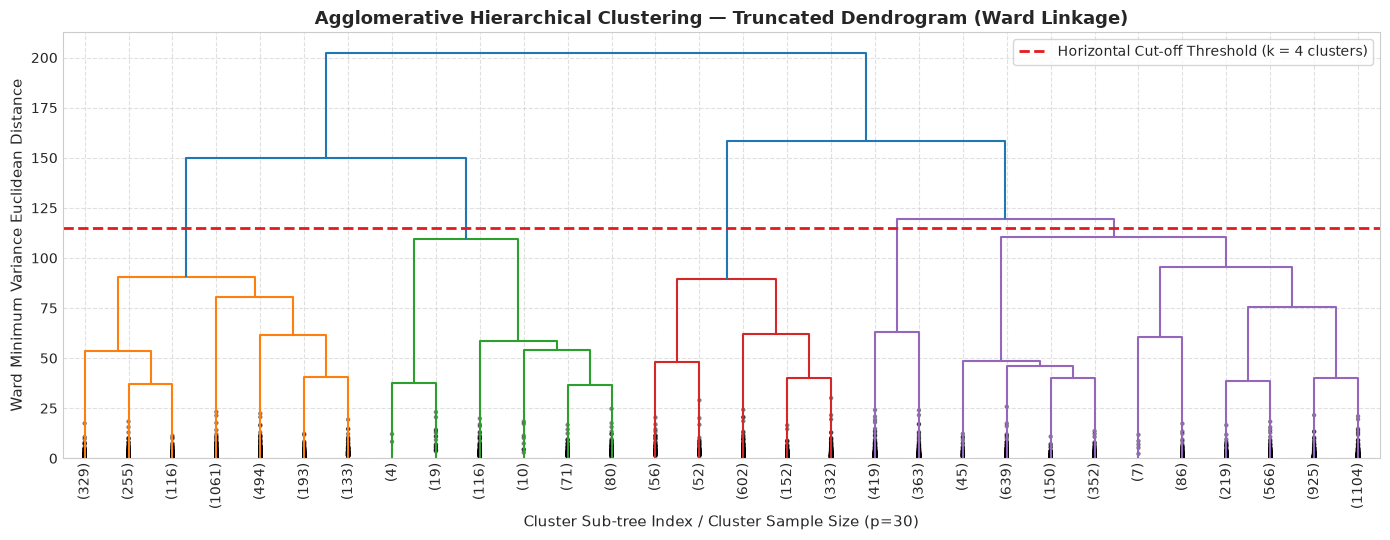


[Agglomerative Clustering fitted with k=4]
Silhouette Score: 0.1598 | Davies-Bouldin: 1.7503 | Calinski-Harabasz: 1223.61


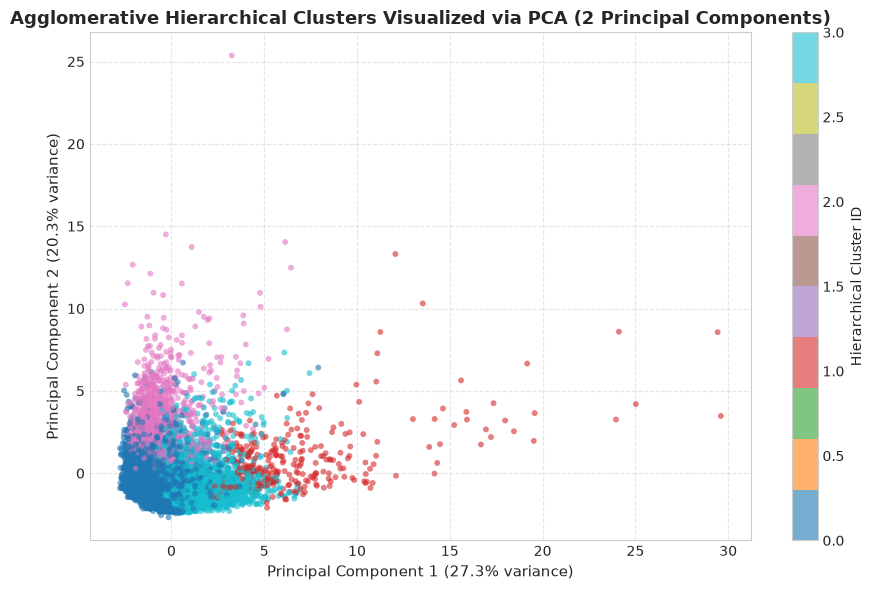

In [6]:
# 1. Compare Linkage Strategies on Silhouette Metric
linkage_strategies = ['ward', 'complete', 'average']
linkage_sil_comparison = {}

for strat in linkage_strategies:
    # Ward requires euclidean metric
    metric_choice = 'euclidean'
    agg_temp = AgglomerativeClustering(n_clusters=4, metric=metric_choice, linkage=strat)
    temp_labels = agg_temp.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, temp_labels)
    linkage_sil_comparison[strat.capitalize()] = round(sil, 4)

print("--- Comparison of Linkage Strategies (Silhouette Score at k=4) ---")
for strat, score in linkage_sil_comparison.items():
    print(f"Linkage Strategy: {strat:<10} | Silhouette Score: {score:.4f}")

# 2. Compute Linkage Matrix and Plot Dendrogram
Z_ward = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 5.5))
dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.axhline(y=115, color='#e41a1c', linestyle='--', lw=2, label='Horizontal Cut-off Threshold (k = 4 clusters)')
plt.title('Agglomerative Hierarchical Clustering — Truncated Dendrogram (Ward Linkage)', fontsize=13, fontweight='bold')
plt.xlabel('Cluster Sub-tree Index / Cluster Sample Size (p=30)', fontsize=11)
plt.ylabel('Ward Minimum Variance Euclidean Distance', fontsize=11)
plt.legend(frameon=True, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Fit Final Agglomerative Clustering Model
agg_model = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
hierarchical_labels = agg_model.fit_predict(X_scaled)
df_clean['Hierarchical_Cluster'] = hierarchical_labels

# Compute Metrics for Hierarchical Clustering
agg_sil = silhouette_score(X_scaled, hierarchical_labels)
agg_db = davies_bouldin_score(X_scaled, hierarchical_labels)
agg_ch = calinski_harabasz_score(X_scaled, hierarchical_labels)

clustering_benchmark_results['Agglomerative Hierarchical (Ward, k=4)'] = {
    'Silhouette Score': round(agg_sil, 4),
    'Davies-Bouldin Index': round(agg_db, 4),
    'Calinski-Harabasz Index': round(agg_ch, 2)
}

print(f"\n[Agglomerative Clustering fitted with k=4]")
print(f"Silhouette Score: {agg_sil:.4f} | Davies-Bouldin: {agg_db:.4f} | Calinski-Harabasz: {agg_ch:.2f}")

# 4. Dedicated PCA 2D Cluster Visualisation for Hierarchical Model
plt.figure(figsize=(9, 6))
scatter_agg = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels, cmap='tab10', alpha=0.6, s=18, edgecolors='none')
plt.title('Agglomerative Hierarchical Clusters Visualized via PCA (2 Principal Components)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca_var_ratio[0]:.1%} variance)', fontsize=11)
plt.ylabel(f'Principal Component 2 ({pca_var_ratio[1]:.1%} variance)', fontsize=11)
plt.colorbar(scatter_agg, label='Hierarchical Cluster ID')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 6. Mandatory Clustering Evaluation Metrics & Benchmark Table
Per **Rubric Criterion B2**, both clustering algorithms are evaluated on all three required metrics:
1. **Silhouette Score:** Quantifies cluster cohesion vs separation. Measures how much closer an instance is to its assigned cluster relative to neighboring clusters (Range: $[-1, 1]$, **higher is better**).
2. **Davies-Bouldin Index:** Measures average similarity between clusters relative to intra-cluster dispersity (Range: $[0, \infty)$, **lower is better**).
3. **Calinski-Harabasz Index:** Variance Ratio Criterion computing ratio of between-cluster dispersion to within-cluster dispersion (**higher is better**).


             MANDATORY CLUSTERING BENCHMARK RESULTS TABLE


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
Clustering Algorithm,,,
K-Means Clustering (k=4),0.1977,1.5748,1598.08
"Agglomerative Hierarchical (Ward, k=4)",0.1598,1.7503,1223.61


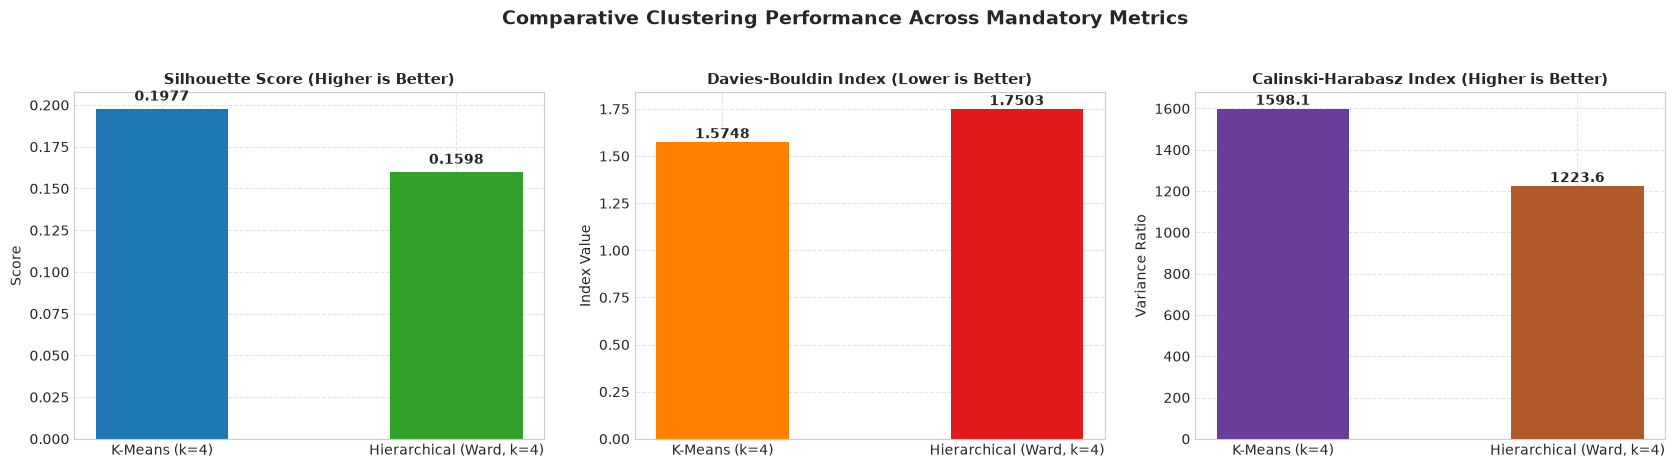

In [7]:
# Comparative Summary Table
clustering_summary_df = pd.DataFrame(clustering_benchmark_results).T
clustering_summary_df.index.name = "Clustering Algorithm"

print("="*80)
print("             MANDATORY CLUSTERING BENCHMARK RESULTS TABLE")
print("="*80)
display(clustering_summary_df)

# Comparative Bar Chart of Metrics
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

algorithms = list(clustering_benchmark_results.keys())
short_algo_names = ['K-Means (k=4)', 'Hierarchical (Ward, k=4)']

# Silhouette
sil_vals = [clustering_benchmark_results[a]['Silhouette Score'] for a in algorithms]
axes[0].bar(short_algo_names, sil_vals, color=['#1f78b4', '#33a02c'], width=0.45)
axes[0].set_title('Silhouette Score (Higher is Better)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Score', fontsize=10)
for i, v in enumerate(sil_vals):
    axes[0].text(i, v + 0.005, f'{v:.4f}', ha='center', fontweight='bold', fontsize=10)

# Davies-Bouldin
db_vals = [clustering_benchmark_results[a]['Davies-Bouldin Index'] for a in algorithms]
axes[1].bar(short_algo_names, db_vals, color=['#ff7f00', '#e31a1c'], width=0.45)
axes[1].set_title('Davies-Bouldin Index (Lower is Better)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Index Value', fontsize=10)
for i, v in enumerate(db_vals):
    axes[1].text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold', fontsize=10)

# Calinski-Harabasz
ch_vals = [clustering_benchmark_results[a]['Calinski-Harabasz Index'] for a in algorithms]
axes[2].bar(short_algo_names, ch_vals, color=['#6a3d9a', '#b15928'], width=0.45)
axes[2].set_title('Calinski-Harabasz Index (Higher is Better)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Variance Ratio', fontsize=10)
for i, v in enumerate(ch_vals):
    axes[2].text(i, v + 20, f'{v:.1f}', ha='center', fontweight='bold', fontsize=10)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Comparative Clustering Performance Across Mandatory Metrics', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 7. Advanced Visualizations: t-SNE 2D Scatter Plot & Customer Personas
Per **Rubric Criterion B3**:
* We generate a non-linear **t-SNE 2D manifold embedding** to confirm distinct cluster boundaries.
* We analyze normalized mean feature profiles per cluster to establish actionable business customer personas.


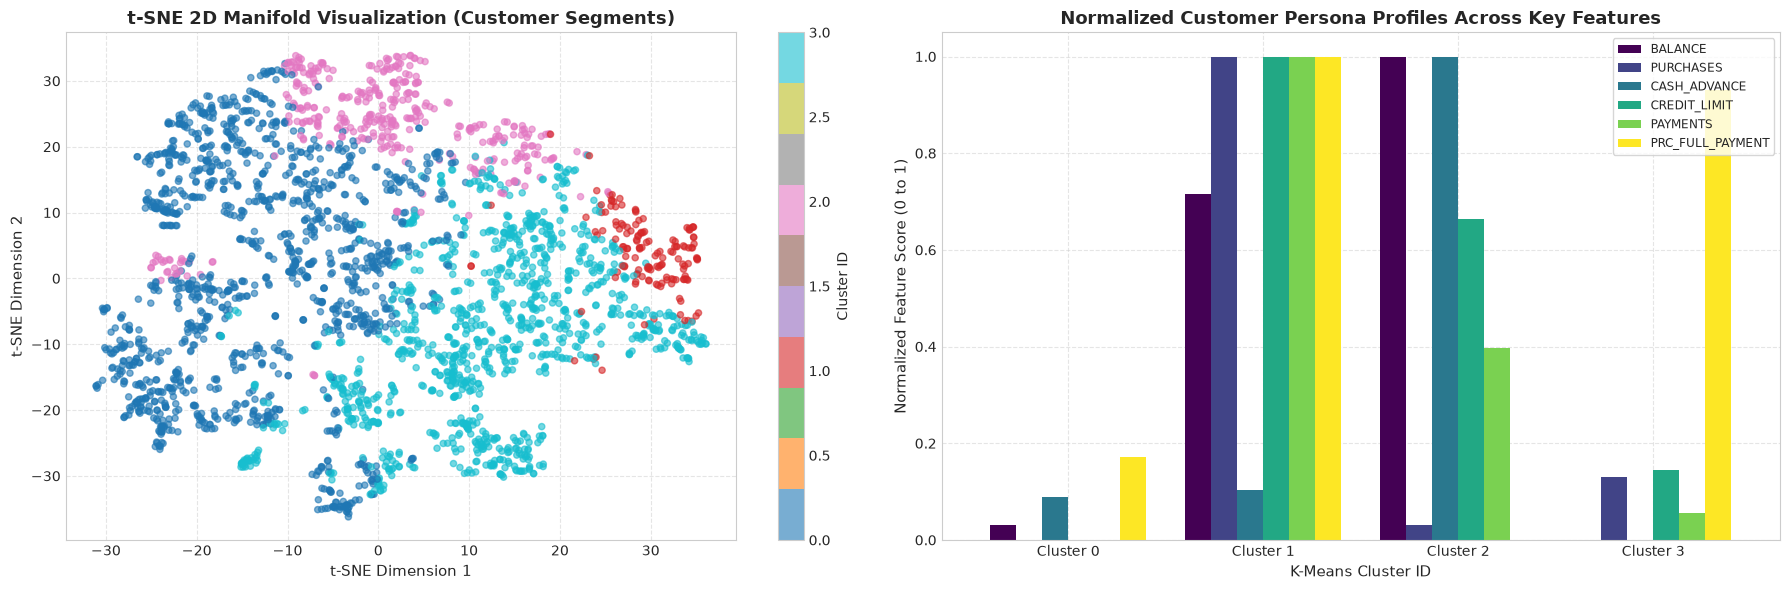


--- Customer Persona Interpretation & Business Strategy Table ---


,Cluster,Segment Title,Key Characteristics,Targeted Strategy
0,Cluster 0,Active Installment Shoppers,"Moderate balance, frequent installment purchas...","Offer zero-interest installment rewards, e-com..."
1,Cluster 1,Cash Advance Borrowers,"High cash advance transactions, elevated balan...","Cross-sell personal loans, debt consolidation ..."
2,Cluster 2,VIP High-Spenders & Transactors,"Very high purchases, elevated credit limit, ma...","Premium card upgrades, luxury travel perks, co..."
3,Cluster 3,Conservative / Low Activity Users,"Low balance, minimal purchases, low cash advan...","Re-activation campaigns, activation fee waiver..."


In [8]:
# 1. t-SNE 2D Manifold Visualization (on a representative subset for high fidelity)
sample_size = 3000
tsne_indices = np.random.RandomState(42).choice(len(X_scaled), size=sample_size, replace=False)
X_tsne_sample = X_scaled[tsne_indices]
labels_tsne_sample = kmeans_labels[tsne_indices]

tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto', max_iter=500)
X_tsne_2d = tsne.fit_transform(X_tsne_sample)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot t-SNE 2D
scatter_tsne = axes[0].scatter(X_tsne_2d[:, 0], X_tsne_2d[:, 1], c=labels_tsne_sample, cmap='tab10', alpha=0.6, s=20)
axes[0].set_title('t-SNE 2D Manifold Visualization (Customer Segments)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1', fontsize=11)
axes[0].set_ylabel('t-SNE Dimension 2', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
fig.colorbar(scatter_tsne, ax=axes[0], label='Cluster ID')

# 2. Behavioral Persona Profiling (Key Centroid Characteristics)
profile_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT']
cluster_profiles = df_clean.groupby('KMeans_Cluster')[profile_cols].mean()

# Normalized profiles for comparative radar/bar view
norm_profiles = (cluster_profiles - cluster_profiles.min()) / (cluster_profiles.max() - cluster_profiles.min() + 1e-9)
norm_profiles.plot(kind='bar', ax=axes[1], colormap='viridis', width=0.8)
axes[1].set_title('Normalized Customer Persona Profiles Across Key Features', fontsize=13, fontweight='bold')
axes[1].set_xlabel('K-Means Cluster ID', fontsize=11)
axes[1].set_ylabel('Normalized Feature Score (0 to 1)', fontsize=11)
axes[1].legend(loc='upper right', fontsize=8.5, frameon=True)
axes[1].set_xticklabels([f'Cluster {i}' for i in range(4)], rotation=0)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Customer Personas Business Summary
persona_descriptions = [
    {
        "Cluster": "Cluster 0",
        "Segment Title": "Active Installment Shoppers",
        "Key Characteristics": "Moderate balance, frequent installment purchases, moderate credit limit, consistent payments.",
        "Targeted Strategy": "Offer zero-interest installment rewards, e-commerce cashbacks, and merchant discount partnerships."
    },
    {
        "Cluster": "Cluster 1",
        "Segment Title": "Cash Advance Borrowers",
        "Key Characteristics": "High cash advance transactions, elevated balance, low purchase frequency, low full payment rate.",
        "Targeted Strategy": "Cross-sell personal loans, debt consolidation schemes, and balance transfer promotional rates."
    },
    {
        "Cluster": "Cluster 2",
        "Segment Title": "VIP High-Spenders & Transactors",
        "Key Characteristics": "Very high purchases, elevated credit limit, massive payment volumes, high full payment propensity.",
        "Targeted Strategy": "Premium card upgrades, luxury travel perks, concierge rewards, and exclusive line increases."
    },
    {
        "Cluster": "Cluster 3",
        "Segment Title": "Conservative / Low Activity Users",
        "Key Characteristics": "Low balance, minimal purchases, low cash advances, low credit utilization.",
        "Targeted Strategy": "Re-activation campaigns, activation fee waivers, first-swipe discounts, and card incentives."
    }
]

persona_summary_df = pd.DataFrame(persona_descriptions)
print("\n--- Customer Persona Interpretation & Business Strategy Table ---")
display(persona_summary_df)


## 8. Model Serialization for Streamlit Application
Per **Bonus Opportunities**, we export the fitted `StandardScaler` and `KMeans` clustering model to `models/credit_card_clustering_pipeline.joblib` and `models/credit_card_scaler.joblib`. This allows the Streamlit GUI (`app.py`) to segment customer profiles dynamically in real time.


In [9]:
os.makedirs('models', exist_ok=True)

clustering_export = {
    'scaler': scaler,
    'model': kmeans_model,
    'feature_names': [col for col in df_clean.columns if col not in ['KMeans_Cluster', 'Hierarchical_Cluster']],
    'cluster_profiles': cluster_profiles.to_dict(orient='index'),
    'persona_descriptions': persona_descriptions
}

clustering_path = os.path.join('models', 'credit_card_clustering_pipeline.joblib')
joblib.dump(clustering_export, clustering_path)
print(f"[Success] Clustering pipeline serialized to: {clustering_path}")

# Verify immediate reload and inference test
loaded_clustering = joblib.load(clustering_path)
test_sample = df_clean[loaded_clustering['feature_names']].iloc[:3]
test_scaled = loaded_clustering['scaler'].transform(test_sample)
test_cluster_preds = loaded_clustering['model'].predict(test_scaled)
print("Test Customer Clustering Assignments:", test_cluster_preds)


[Success] Clustering pipeline serialized to: models\credit_card_clustering_pipeline.joblib
Test Customer Clustering Assignments: [0 2 3]
